Libraries imported successfully!
Upload train.csv, test.csv and sampleSubmission.csv


Saving sampleSubmission.csv to sampleSubmission (2).csv
Saving test.csv to test (2).csv
Saving train.csv to train (2).csv

Training Dataset: (10886, 12)
Testing Dataset: (6493, 9)

Preprocessing completed!
Features: (17379, 25)

========== ANN MODEL ==========
Epoch 1/60
137/137 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 2.9859 - mae: 1.2407 - val_loss: 1.1418 - val_mae: 0.8495
Epoch 2/60
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.5056 - mae: 0.8210 - val_loss: 0.9850 - val_mae: 0.7870
Epoch 3/60
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.0083 - mae: 0.7525 - val_loss: 0.8940 - val_mae: 0.7671
Epoch 4/60
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.8607 - mae: 0.7070 - val_loss: 0.9121 - val_mae: 0.7890
Epoch 5/60
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6929 - mae: 0.6467 - val_loss: 0.7478 - val_mae: 0.7288
Epoch 6/60
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.5858 - mae: 0.6009 - val_loss: 0.4792 - val_mae: 0.5776
Epoch 7/60
137/137 ━━━━━━━━━━━━

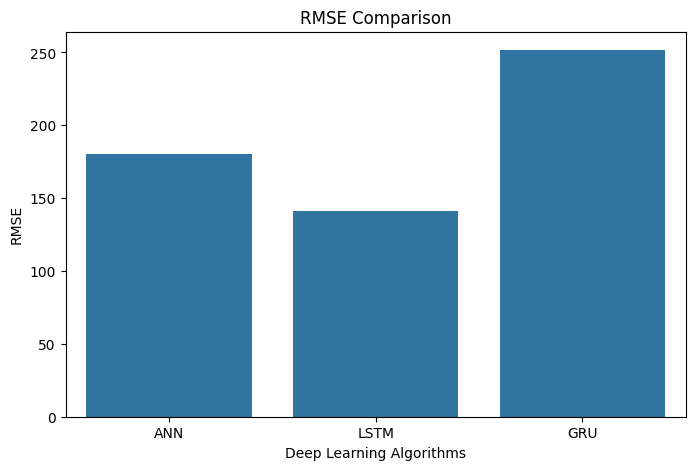

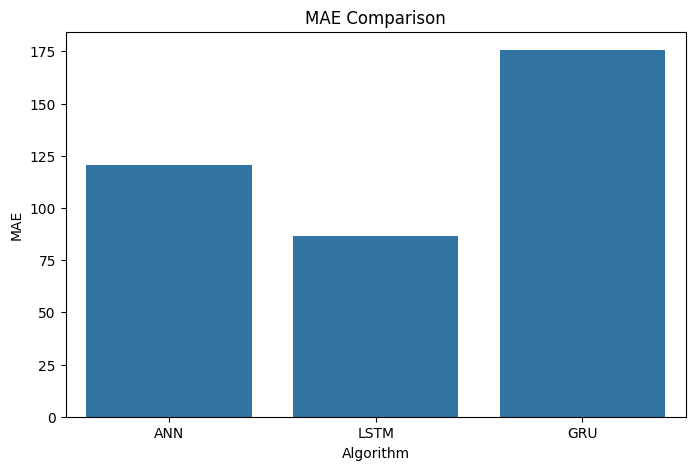

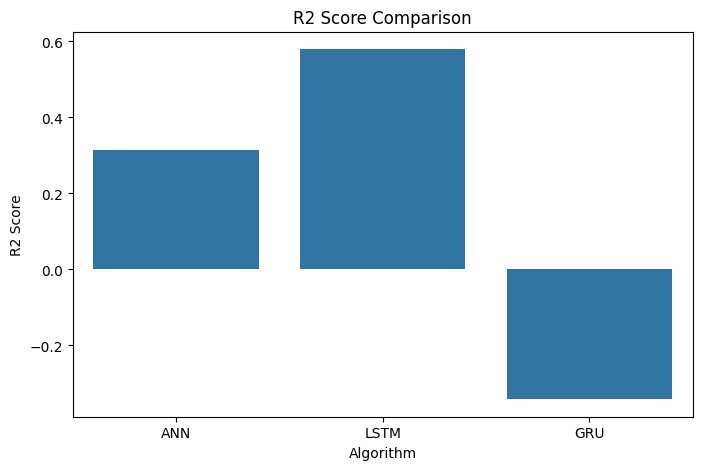

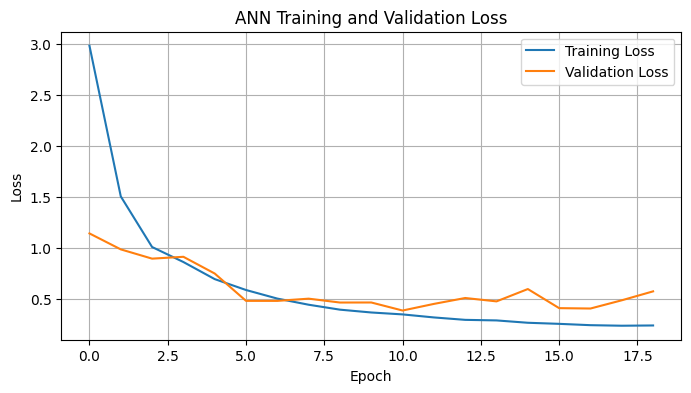

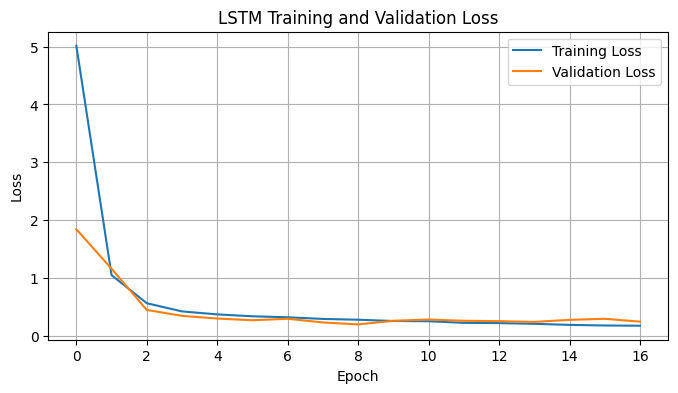

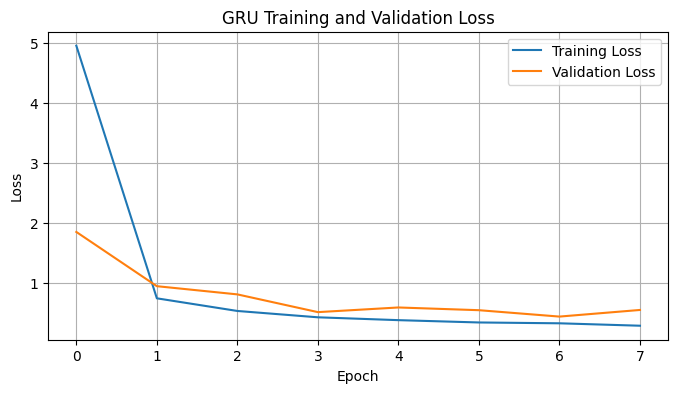

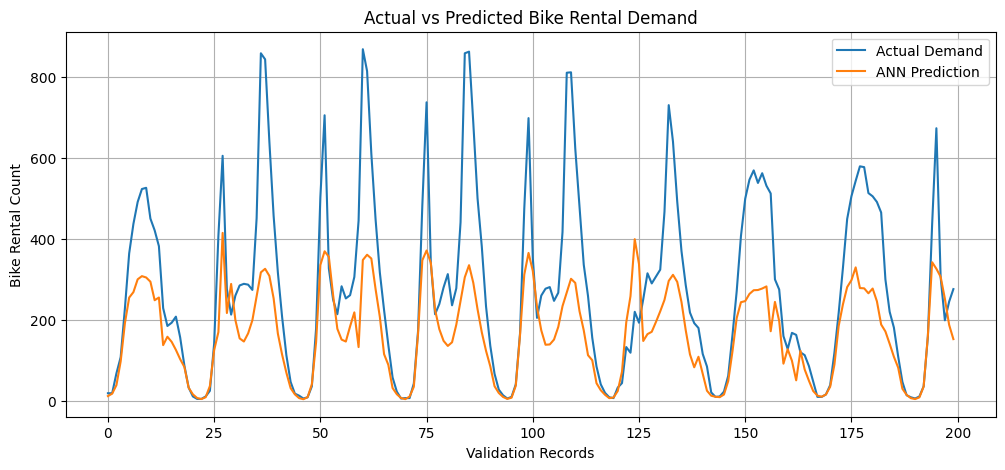


 ANN_predictions.csv created successfully!


,datetime,count
0,2011-01-20 00:00:00,10
1,2011-01-20 01:00:00,7
2,2011-01-20 02:00:00,3
3,2011-01-20 03:00:00,2
4,2011-01-20 04:00:00,3



 LSTM_predictions.csv created successfully!


,datetime,count
0,2011-01-20 00:00:00,10
1,2011-01-20 01:00:00,7
2,2011-01-20 02:00:00,3
3,2011-01-20 03:00:00,2
4,2011-01-20 04:00:00,2



 GRU_predictions.csv created successfully!


,datetime,count
0,2011-01-20 00:00:00,10
1,2011-01-20 01:00:00,7
2,2011-01-20 02:00:00,3
3,2011-01-20 03:00:00,5
4,2011-01-20 04:00:00,7


... (4 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Project completed successfully!


In [ ]:

# ============================================================
# BIKE RENTAL DEMAND PREDICTION USING DEEP LEARNING
# Algorithms: ANN, LSTM and GRU
# Platform: Google Colab
# ============================================================

!pip install -q tensorflow scikit-learn pandas numpy matplotlib seaborn

# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import mean_squared_log_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM, GRU
from tensorflow.keras.callbacks import EarlyStopping

print("Libraries imported successfully!")

# 2. UPLOAD DATASETS
print("Upload train.csv, test.csv and sampleSubmission.csv")
uploaded = files.upload()

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample = pd.read_csv("sampleSubmission.csv")

print("\nTraining Dataset:", train.shape)
print("Testing Dataset:", test.shape)

# 3. DATA PREPROCESSING
train["source"] = "train"
test["source"] = "test"

train["row_id"] = np.arange(len(train))
test["row_id"] = np.arange(len(test))

data = pd.concat([train, test], ignore_index=True)

data["datetime"] = pd.to_datetime(data["datetime"])
data = data.sort_values("datetime").reset_index(drop=True)

# Extract date and time features
data["hour"] = data["datetime"].dt.hour
data["day"] = data["datetime"].dt.day
data["month"] = data["datetime"].dt.month
data["year"] = data["datetime"].dt.year
data["weekday"] = data["datetime"].dt.dayofweek

# Cyclical encoding
data["hour_sin"] = np.sin(2*np.pi*data["hour"]/24)
data["hour_cos"] = np.cos(2*np.pi*data["hour"]/24)
data["month_sin"] = np.sin(2*np.pi*data["month"]/12)
data["month_cos"] = np.cos(2*np.pi*data["month"]/12)
data["weekday_sin"] = np.sin(2*np.pi*data["weekday"]/7)
data["weekday_cos"] = np.cos(2*np.pi*data["weekday"]/7)

# Select common input features
features = data[
    ["holiday", "workingday", "temp", "atemp",
     "humidity", "windspeed", "hour", "day",
     "month", "year", "weekday",
     "hour_sin", "hour_cos",
     "month_sin", "month_cos",
     "weekday_sin", "weekday_cos"]
].copy()

# One-hot encoding
features = pd.concat([
    features,
    pd.get_dummies(data["season"], prefix="season", dtype=int),
    pd.get_dummies(data["weather"], prefix="weather", dtype=int)
], axis=1)

train_mask = data["source"].eq("train").to_numpy()
test_mask = data["source"].eq("test").to_numpy()

# Scale features
scaler = StandardScaler()
scaler.fit(features.loc[train_mask])

X_all = scaler.transform(features)

y_all = data["count"].to_numpy(dtype=float)

print("\nPreprocessing completed!")
print("Features:", X_all.shape)

# 4. TRAIN AND VALIDATION SPLIT
train_positions = np.where(train_mask)[0]

split = int(len(train_positions) * 0.8)

ann_train_idx = train_positions[:split]
ann_val_idx = train_positions[split:]

X_ann_train = X_all[ann_train_idx]
X_ann_val = X_all[ann_val_idx]

y_ann_train = np.log1p(y_all[ann_train_idx])
y_ann_val = np.log1p(y_all[ann_val_idx])

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

# 5. ANN MODEL
print("\n========== ANN MODEL ==========")

ann_model = Sequential([
    tf.keras.Input(shape=(X_all.shape[1],)),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

ann_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

ann_history = ann_model.fit(
    X_ann_train,
    y_ann_train,
    validation_data=(X_ann_val, y_ann_val),
    epochs=60,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

ann_val_pred = np.expm1(
    ann_model.predict(X_ann_val, verbose=0).ravel()
)

ann_val_pred = np.maximum(ann_val_pred, 0)

# 6. CREATE SEQUENCES FOR LSTM AND GRU
print("\nPreparing time-series sequences...")

sequence_length = 24

X_sequences = []
target_indices = []

timestamps = data["datetime"].reset_index(drop=True)

for i in range(sequence_length - 1, len(data)):

    start = i - sequence_length + 1

    time_diff = timestamps.iloc[start:i+1].diff().dropna()

    if (time_diff == pd.Timedelta(hours=1)).all():

        X_sequences.append(X_all[start:i+1])
        target_indices.append(i)

X_sequences = np.array(X_sequences)
target_indices = np.array(target_indices)

seq_train_mask = train_mask[target_indices]

X_seq_train_all = X_sequences[seq_train_mask]

seq_target_idx = target_indices[seq_train_mask]

y_seq_all = np.log1p(y_all[seq_target_idx])

seq_split = int(len(X_seq_train_all) * 0.8)

X_seq_train = X_seq_train_all[:seq_split]
X_seq_val = X_seq_train_all[seq_split:]

y_seq_train = y_seq_all[:seq_split]
y_seq_val = y_seq_all[seq_split:]

print("Sequence training:", X_seq_train.shape)
print("Sequence validation:", X_seq_val.shape)

# 7. LSTM MODEL
print("\n========== LSTM MODEL ==========")

lstm_model = Sequential([
    tf.keras.Input(
        shape=(sequence_length, X_all.shape[1])
    ),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

lstm_history = lstm_model.fit(
    X_seq_train,
    y_seq_train,
    validation_data=(X_seq_val, y_seq_val),
    epochs=60,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

lstm_val_pred = np.expm1(
    lstm_model.predict(X_seq_val, verbose=0).ravel()
)

lstm_val_pred = np.maximum(lstm_val_pred, 0)

# 8. GRU MODEL
print("\n========== GRU MODEL ==========")

gru_model = Sequential([
    tf.keras.Input(
        shape=(sequence_length, X_all.shape[1])
    ),
    GRU(64, return_sequences=True),
    Dropout(0.2),
    GRU(32),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

gru_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

gru_history = gru_model.fit(
    X_seq_train,
    y_seq_train,
    validation_data=(X_seq_val, y_seq_val),
    epochs=60,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

gru_val_pred = np.expm1(
    gru_model.predict(X_seq_val, verbose=0).ravel()
)

gru_val_pred = np.maximum(gru_val_pred, 0)

# 9. MODEL EVALUATION
def evaluate_model(name, actual, predicted):

    predicted = np.maximum(predicted, 0)

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    rmsle = np.sqrt(
        mean_squared_log_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    return {
        "Algorithm": name,
        "MAE": mae,
        "RMSE": rmse,
        "RMSLE": rmsle,
        "R2 Score": r2
    }

ann_actual = y_all[ann_val_idx]
seq_actual = y_all[seq_target_idx[seq_split:]]

results = pd.DataFrame([
    evaluate_model("ANN", ann_actual, ann_val_pred),
    evaluate_model("LSTM", seq_actual, lstm_val_pred),
    evaluate_model("GRU", seq_actual, gru_val_pred)
])

print("\n========== MODEL COMPARISON ==========")
print(results.round(4).to_string(index=False))

# 10. RMSE COMPARISON GRAPH
plt.figure(figsize=(8, 5))
sns.barplot(data=results, x="Algorithm", y="RMSE")
plt.title("RMSE Comparison")
plt.xlabel("Deep Learning Algorithms")
plt.ylabel("RMSE")
plt.show()

# 11. MAE COMPARISON GRAPH
plt.figure(figsize=(8, 5))
sns.barplot(data=results, x="Algorithm", y="MAE")
plt.title("MAE Comparison")
plt.show()

# 12. R2 SCORE GRAPH
plt.figure(figsize=(8, 5))
sns.barplot(data=results, x="Algorithm", y="R2 Score")
plt.title("R2 Score Comparison")
plt.show()

# 13. TRAINING LOSS GRAPHS
histories = {
    "ANN": ann_history,
    "LSTM": lstm_history,
    "GRU": gru_history
}

for name, history in histories.items():

    plt.figure(figsize=(8, 4))

    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")

    plt.title(name + " Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid()
    plt.show()

# 14. ACTUAL VS PREDICTED GRAPH
plt.figure(figsize=(12, 5))

plt.plot(
    ann_actual[:200],
    label="Actual Demand"
)

plt.plot(
    ann_val_pred[:200],
    label="ANN Prediction"
)

plt.title("Actual vs Predicted Bike Rental Demand")
plt.xlabel("Validation Records")
plt.ylabel("Bike Rental Count")
plt.legend()
plt.grid()
plt.show()

# 15. PREPARE TEST SEQUENCES
seq_test_mask = test_mask[target_indices]

X_test_seq = X_sequences[seq_test_mask]
test_seq_indices = target_indices[seq_test_mask]

# Predict test dataset using ANN
X_test_ann = X_all[test_mask]

ann_test_pred = np.expm1(
    ann_model.predict(X_test_ann, verbose=0).ravel()
)

ann_test_pred = np.maximum(ann_test_pred, 0)

# Predict test dataset using LSTM
lstm_test_pred = np.expm1(
    lstm_model.predict(X_test_seq, verbose=0).ravel()
)

lstm_test_pred = np.maximum(lstm_test_pred, 0)

# Predict test dataset using GRU
gru_test_pred = np.expm1(
    gru_model.predict(X_test_seq, verbose=0).ravel()
)

gru_test_pred = np.maximum(gru_test_pred, 0)

# 16. CREATE SUBMISSION FILES
test_dates = data.loc[test_mask, "datetime"].to_numpy()

ann_map = dict(zip(test_dates, ann_test_pred))

seq_test_dates = data.loc[
    test_seq_indices, "datetime"
].to_numpy()

lstm_map = dict(zip(seq_test_dates, lstm_test_pred))
gru_map = dict(zip(seq_test_dates, gru_test_pred))

sample_dates = pd.to_datetime(sample["datetime"])

def create_submission(prediction_map, filename):

    predictions = sample_dates.map(
        lambda dt: prediction_map.get(
            dt, ann_map.get(dt, 0)
        )
    )

    submission = sample.copy()

    submission["count"] = np.rint(
        np.maximum(predictions.to_numpy(), 0)
    ).astype(int)

    submission.to_csv(filename, index=False)

    print("\n", filename, "created successfully!")
    display(submission.head())

    return submission

ann_submission = create_submission(
    ann_map, "ANN_predictions.csv"
)

lstm_submission = create_submission(
    lstm_map, "LSTM_predictions.csv"
)

gru_submission = create_submission(
    gru_map, "GRU_predictions.csv"
)

# 17. FINAL RESULT
best_model = results.loc[results["RMSE"].idxmin(), "Algorithm"]

print("\n===================================")
print("BIKE RENTAL DEMAND PREDICTION DONE")
print("===================================")
print("Best model based on validation RMSE:", best_model)
print("ANN, LSTM and GRU training completed!")
print("All prediction files generated!")

# 18. DOWNLOAD PREDICTION FILES
files.download("ANN_predictions.csv")
files.download("LSTM_predictions.csv")
files.download("GRU_predictions.csv")

print("\nProject completed successfully!")
